In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
import argparse
import os
import random
import argparse
from karateclub import NetLSD, Graph2Vec, FeatherGraph
from grakel import GraphKernel
import toper

from sklearn.manifold import MDS
from sklearn.decomposition import PCA

from magnipy.magnitude.distances import get_dist

from diversity_curves.process import get_mag_graphs, get_funs_df, get_mag_funs_graphs
from diversity_curves.simulate import simulate_graphs_kwargs
from diversity_curves.classifiers import knn_classifier
from diversity_curves.clustering_performance import compute_clustering_scores_resample, compute_silhouette_score_resamples, compute_rand_agglo, compute_rand_kmeans, all_clustering_results_euclidean
from diversity_curves.baselines.spectral_zoo import est_moment
from diversity_curves.baselines.ph import obtain_input_from_graphs

# scratch space creating script

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib
import argparse
import os
import random

from grakel import GraphKernel
from karateclub import NetLSD, Graph2Vec, FeatherGraph
import toper

from sklearn.manifold import MDS
from sklearn.decomposition import PCA

from magnipy.magnitude.distances import get_dist
from diversity_curves.process import get_mag_graphs, get_funs_df, get_mag_funs_graphs

from diversity_curves.simulate import simulate_graphs_kwargs
from diversity_curves.classifiers import knn_classifier
from diversity_curves.clustering_performance import (
    compute_clustering_scores_resample,
    compute_silhouette_score_resamples,
    compute_rand_agglo,
    compute_rand_kmeans,
    all_clustering_results_euclidean,
    all_clustering_results_euclidean_append,
)
from diversity_curves.baselines.spectral_zoo import est_moment
from diversity_curves.baselines.ph import obtain_input_from_graphs

if True:


    # argparser = argparse.ArgumentParser()
    # argparser.add_argument(
    #     "--output_dir",
    #     type=str,
    #     default="./simulations/results/ablations/",
    #     help="Output directory for results",
    # )
    # argparser.add_argument(
    #     "--ngraphs",
    #     type=int,
    #     default=3,
    #     help="Number of graphs that are generated per cardinality",
    # )
    # argparser.add_argument(
    #     "--nrange",
    #     type=int,
    #     nargs=2,
    #     default=[10, 30],
    #     help="specify the range of cardinalities of the generated graphs",
    # )
    # argparser.add_argument(
    #     "--nsteps",
    #     type=int,
    #     default=1,
    #     help="Specify the stepsize for the cardinalities of the generated graphs",
    # )
    # argparser.add_argument(
    #     '--nreps',
    #     type=int,
    #     default=1,
    #     help='Specify the number of repetitions in the diversity curves computation'
    # )
    # argparser.add_argument(
    #     '--nseed',
    #     type=int,
    #     default=10,
    #     help='specify the number of different seeds for the ablation study',
    # )

    # args = argparser.parse_args()
    # results_dir = args.output_dir
    n_low = 10
    n_high = 30
    n_steps = 1
    n_graphs = 3
    n_rep = 1
    n_seeds = 3

    # Setting the parameters as reported in the paper
    model_params = {
        "ER": {
            "ER_probs": [0.75],
            "ER_nps": None,
        },
        "RPG": {
            "RPG_probs": [[0.9, 0.1]],
            "RPG_props": [1 / 3, 1 / 3],
        },
        "SBM": {"SBM_probs": [0.8, 0.05], "SBM_blocks": [[1 / 4, 1 / 4, 1 / 4]]},
        "RG": {"RG_probs": [0.25]},
    }

    # choice of graph metric we use for the spread computation
    graph_metrics = ["shortest_path_distance"]

    # get configuration of all models
    models = list(model_params.keys())
    all_configs = {}
    for model in models:
        model_config = tuple(
            model_params[model][param] for param in model_params[model].keys()
        )
        all_configs[model] = model_config
    configuration = tuple(all_configs[model] for model in models)

    noderange = range(n_low, n_high, n_steps)
    downsample_to = None

    scores = [
        "acc_mean",
        "silh_mean",
        "ari_agglo_mean",
        "db_mean",
        "ch_mean",
        "ari_kmeans_mean",
    ]
    scores_asc = {
        "acc_mean": False,
        "silh_mean": False,
        "ari_agglo_mean": False,
        "db_mean": True,
        "ch_mean": False,
        "ari_kmeans_mean": False,
    }

    res_dict = {}

    # if not os.path.exists(results_dir):
    #     os.makedirs(results_dir, exist_ok=True)

    avg_diffs = []
    std_diffs = []
    all_diffs = []
    avg_rand_diffs = []
    std_rand_diffs = []
    all_rand_diffs = []
    accs_seeds = {}

    # generate the graphs of all models and create label per model
    G_nx = []
    Gs = []
    n_nodes = []
    y_models = []
    class_labels = {}
    for i_m, model in enumerate(model_params):
        model_kwargs = model_params[model]
        print(f"model {model} kwargs {model_kwargs}")
        G_nx_model, Gs_model, y_model, y_probs_model, n_nodes_model = (
            simulate_graphs_kwargs(
                model=model,
                n_graphs=n_graphs,
                nodes_range=noderange,
                **model_kwargs,
            )
        )
        G_nx.extend(G_nx_model)
        Gs.extend(Gs_model)
        n_nodes.extend(n_nodes_model)
        y_models.extend([i_m] * len(G_nx_model))
        class_labels[i_m] = model

    upsample_to = max(n_nodes)
    y = y_models
    hue_names = [class_labels[i] for i in y]

    # setting parameters for plots
    sns.set_style("white")
    matplotlib.rcParams.update({"font.size": 20})

    ##################################
    ### computing diversity curves ###
    ##################################

    for metric in graph_metrics:

        mag_funs_per_seed = []
    
        res_dict[f"divcurves_{metric}"] = {}
        res_dict[f"divcurves_pca_{metric}"] = {}
        accs_seeds[f"divcurves_{metric}"] = []
        accs_seeds[f"divcurves_pca_{metric}"] = []

        for score in scores:
            res_dict[f"divcurves_{metric}"][score] = []
            res_dict[f"divcurves_pca_{metric}"][score] = []
            score_std = score[:-4]+'std'
            res_dict[f"divcurves_{metric}"][score_std] = []
            res_dict[f"divcurves_pca_{metric}"][score_std] = []

        for seed in range(n_seeds):
            np.random.seed(seed)
            random.seed(seed)
            
            print(f"Computing MAG with metric: {metric} for seed: {seed}")

            def dist_fn(G):
                return get_dist(G=G, X=None, X2=None, metric=metric, mode="structure")

            all_spreads, weights_lists = get_mag_graphs(
                G_nx,
                dist_fn,
                ts=[1],
                upsample_to=upsample_to,
                downsample_to=downsample_to,
                n_repeats=n_rep,
                scores_method='random',
                mode='structure',
                set_seed=False
            )

            mag_funs = get_funs_df(all_spreads)
            mag_funs_interpolated = mag_funs.interpolate(method="linear", axis="columns")

            mag_funs_per_seed.append(mag_funs_interpolated)

            # # compute clustering metrics based on euclidean distance of diversity curve vectors
            # ari_kmeans_mean, ari_kmeans_std = compute_rand_kmeans(
            #     np.array(mag_funs_interpolated), y
            # )
            # ari_agglo_mean, ari_agglo_std = compute_rand_agglo(
            #     np.array(mag_funs_interpolated), y, metric="euclidean"
            # )

            # means, stds = compute_clustering_scores_resample(
            #     np.array(mag_funs_interpolated), y
            # )


            # res_dict[f"divcurves_{metric}"]["silh_mean"].append(means[0]),
            # res_dict[f"divcurves_{metric}"]["db_mean"].append(means[1]),
            # res_dict[f"divcurves_{metric}"]["ch_mean"].append(means[2]),

            # res_dict[f"divcurves_{metric}"]["silh_std"].append(means[0]),
            # res_dict[f"divcurves_{metric}"]["db_std"].append(means[1]),
            # res_dict[f"divcurves_{metric}"]["ch_std"].append(means[2]),

            # res_dict[f"divcurves_{metric}"]["ari_agglo_mean"].append(ari_agglo_mean)
            # res_dict[f"divcurves_{metric}"]["ari_agglo_std"].append(ari_agglo_std)
            # res_dict[f"divcurves_{metric}"]["ari_kmeans_mean"].append(ari_kmeans_mean)
            # res_dict[f"divcurves_{metric}"]["ari_kmeans_std"].append(ari_kmeans_std)

            # computing accuracies
            if n_graphs > 1:
                test_accs = knn_classifier(
                    np.array(mag_funs_interpolated),
                    np.array(y),
                    precomputed=False,
                    groups=np.array(n_nodes),
                )
            else:
                test_accs = knn_classifier(
                    np.array(mag_funs_interpolated), np.array(y), precomputed=False
                )

            accs_seeds[f"divcurves_{metric}"].append(test_accs)
            res_dict[f"divcurves_{metric}"]["acc_mean"].append(np.mean(test_accs))
            res_dict[f"divcurves_{metric}"]["acc_std"].append(np.std(test_accs))
            all_clustering_results_euclidean_append(f"divcurves_{metric}", res_dict, np.array(mag_funs_interpolated), y)

            # doing PCA with Euclidean distance between the diversity curves
            pca_embedding = PCA(n_components=2)
            X_pca = pca_embedding.fit_transform(np.array(mag_funs_interpolated))

            # computing clustering scores and accuracies on transformed data from PCA
            if n_graphs > 1:
                test_accs = knn_classifier(
                    X_pca, np.array(y), precomputed=False, groups=np.array(n_nodes)
                )
            else:
                test_accs = knn_classifier(X_pca, np.array(y), precomputed=False)
            accs_seeds[f"divcurves_pca_{metric}"].append(test_accs)
            res_dict[f"divcurves_pca_{metric}"]["acc_mean"].append(np.mean(test_accs))
            res_dict[f"divcurves_pca_{metric}"]["acc_std"].append(np.std(test_accs))
            all_clustering_results_euclidean_append(f"divcurves_pca_{metric}", res_dict, X_pca, y)

            # # creating plots
            # fig = sns.scatterplot(
            #     x=X_pca[:, 0], y=X_pca[:, 1], hue=hue_names, palette="tab10"
            # )
            # fig.legend(frameon=False, loc=(1.04, 0), bbox_to_anchor=(1, 0.5))
            # sns.despine()
            # plt.savefig(
            #     results_dir + f"divcurves_pca_{metric}_nreps_{n_rep}.pdf",
            #     dpi=300,
            #     format="pdf",
            #     bbox_inches="tight",
            # )
            # plt.savefig(
            #     results_dir + f"divcurves_pca_{metric}_nreps_{n_rep}.png",
            #     dpi=300,
            #     format="png",
            #     bbox_inches="tight",
            # )
            # plt.close()

        #compute mean curve over all repeats
        df_mag_funs_all_seeds = pd.concat([mag_funs_per_seed[i] for i in range(n_seeds)])
        df_mean_curve = df_mag_funs_all_seeds.groupby(df_mag_funs_all_seeds.index).mean()

        # mean and std (over all graphs) for l2 distance in difference seeds
        for seed_i in range(n_seeds):
            # getting a difference between the curves from random seed
            l2_differences = []
            for graph_index in df_mean_curve.index:
                this_curve, mean_curve = mag_funs_per_seed[seed_i].loc[graph_index], df_mean_curve.loc[graph_index]
                l2norm = np.linalg.norm([this_curve - mean_curve], ord=None)
                l2_differences.append(l2norm)
                all_diffs.append(l2norm)
            avg_diffs.append(np.mean(l2_differences))
            std_diffs.append(np.std(l2_differences))

        #as a control we plot the mean distances between some randomly picked graphs

        # mean and std (over all graphs) for l2 distance in difference seeds to the mean curve
        for seed_i in range(n_seeds):
            # getting a difference between the curves from random seed
            l2_differences = []
            
            for graph_index in df_mean_curve.index:
                other_graph = np.random.choice(np.delete(list(df_mean_curve.index),graph_index))
                this_curve, other_curve = mag_funs_per_seed[seed_i].loc[graph_index], df_mean_curve.loc[other_graph]
                l2norm = np.linalg.norm([this_curve - other_curve], ord=None)
                l2_differences.append(l2norm)
                all_rand_diffs.append(l2norm)
            avg_rand_diffs.append(np.mean(l2_differences))
            std_rand_diffs.append(np.std(l2_differences))
        
    # creating dataframes and saving results
    tuples = {(i,j): res_dict[i][j] 
       for i in res_dict.keys() 
       for j in res_dict[i].keys()}
    res_df = pd.DataFrame(list(tuples.values()), index=pd.MultiIndex.from_tuples(tuples.keys()))

    all_diffs_dict = {
        'same': all_diffs,
        'rand': all_rand_diffs 
    }

    all_diffs_df = pd.DataFrame.from_dict(all_diffs_dict, orient='index')

    seed_diffs_dict = {
        'same_mean': avg_diffs,
        'same_std': std_diffs,
        'rand_mean': avg_rand_diffs,
        'rand_std': std_rand_diffs,
    }

    seed_diffs_df = pd.DataFrame.from_dict(seed_diffs_dict, orient='index')

    accuracies_tuples = {(i,j): accs_seeds[i][j] 
       for i in accs_seeds.keys() 
       for j in range(len(accs_seeds[i]))}
    accs_seeds_df = pd.DataFrame(list(accuracies_tuples.values()), index=pd.MultiIndex.from_tuples(accuracies_tuples.keys()))
    # res_df.to_csv(f"{results_dir}/res_df.csv")
    # all_diffs_df.to_csv(f'{results_dir}/all_diffs.csv')
    # seed_diffs_df.to_csv(f'{results_dir}/seed_diffs.csv')
    # avg_accs_seeds_df.to_csv(f'{results_dir}/avg_accs_seed.csv')
    # df_n_nodes.to_csv(f"{results_dir}/n_nodes.csv")


model ER kwargs {'ER_probs': [0.75], 'ER_nps': None}
model RPG kwargs {'RPG_probs': [[0.9, 0.1]], 'RPG_props': [0.3333333333333333, 0.3333333333333333]}
model SBM kwargs {'SBM_probs': [0.8, 0.05], 'SBM_blocks': [[0.25, 0.25, 0.25]]}
model RG kwargs {'RG_probs': [0.25]}
Computing MAG with metric: shortest_path_distance for seed: 0
Fold 0: test accuracy = 0.8333 (k=5)
Fold 1: test accuracy = 0.8333 (k=5)
Fold 2: test accuracy = 0.9167 (k=5)
Fold 3: test accuracy = 0.8750 (k=5)
Fold 4: test accuracy = 0.8750 (k=5)
Fold 5: test accuracy = 0.9167 (k=5)
Fold 6: test accuracy = 0.9167 (k=5)
Fold 7: test accuracy = 0.9583 (k=5)
Fold 8: test accuracy = 0.7917 (k=5)
Fold 9: test accuracy = 0.8750 (k=5)

Mean test accuracy: 0.8792
Std test accuracy:  0.0473
Silhouette Score: 0.425 ± 0.034
Davies-Bouldin Score: 0.750 ± 0.060
Calinski-Harabasz Score: 195.898 ± 34.544
Fold 0: test accuracy = 0.8333 (k=5)
Fold 1: test accuracy = 0.7500 (k=5)
Fold 2: test accuracy = 0.9167 (k=5)
Fold 3: test accuracy 

In [6]:
mag_funs_per_seed[0]

index,1,2,3,4,5,6,7,8,9,10,...,20,21,22,23,24,25,26,27,28,29
graph,,,,,,,,,,,,,,,,,,,,,
0,1.0,1.462117,1.728351,1.901468,2.023048,2.113125,2.182537,2.276583,2.346083,2.428705,...,2.631074,2.644786,2.655487,2.652327,2.680105,2.704477,2.714726,2.708670,2.703469,2.698992
1,1.0,1.462117,1.728351,1.901468,2.023048,2.113125,2.231284,2.318411,2.384705,2.492529,...,2.707051,2.713305,2.720802,2.744599,2.791866,2.798166,2.820789,2.806388,2.793795,2.782738
2,1.0,1.462117,1.728351,1.901468,2.107095,2.244946,2.448092,2.586048,2.683793,2.710649,...,2.965976,2.931462,2.970243,2.968087,3.003673,2.997698,2.998437,3.012658,3.031401,3.048064
3,1.0,1.462117,1.728351,2.019627,2.200884,2.322092,2.407396,2.469771,2.516760,2.642279,...,2.947779,2.936520,2.957109,2.939707,2.956678,2.975528,2.975661,2.963462,2.952301,3.023400
4,1.0,1.462117,1.728351,1.901468,2.107095,2.175958,2.284166,2.404978,2.483865,2.574386,...,2.866987,2.875187,2.895408,2.929467,2.939702,2.933918,2.932142,2.946588,2.948491,2.934995
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235,1.0,2.000000,3.000000,3.462117,3.906599,4.154556,4.576262,4.835962,5.298079,5.338666,...,7.809323,8.230831,8.355034,8.503277,8.958959,9.183102,9.442393,9.657312,9.752359,9.862834
236,1.0,2.000000,2.462117,2.924234,3.368716,3.616673,4.061155,4.214842,4.456121,4.704078,...,6.705100,7.034408,7.180883,7.230171,7.508894,7.817412,8.056323,8.323724,8.782096,8.857264
237,1.0,2.000000,3.000000,3.462117,3.906599,4.154556,4.308244,4.706247,4.866567,5.254393,...,7.198504,7.249567,7.290918,7.532178,7.866393,7.965163,8.063196,8.354472,8.597034,8.630733


In [16]:
comp_method = 'different_group'
all_diffs_nomean = []
all_rand_diffs_nomean = []
for seed_i in range(n_seeds):
    for seed_j in range(seed_i+1, n_seeds):
        for graph_index in df_mean_curve.index:
            curve_i, curve_j = mag_funs_per_seed[seed_i].loc[graph_index], mag_funs_per_seed[seed_j].loc[graph_index]
            l2norm = np.linalg.norm([curve_i - curve_j], ord=None)
            all_diffs_nomean.append(l2norm)

#control with random curves
for seed_i in range(n_seeds):
    for seed_j in range(seed_i+1, n_seeds):
        for graph_index in df_mean_curve.index:
            if comp_method == 'all_but_self':
                other_graphs = np.delete(list(df_mean_curve.index), graph_index)
            elif comp_method == 'different_group':
                this_label = y[graph_index]
                other_graphs = [i for i in df_mean_curve.index if y[i] != this_label]
            else:
                print('Choose comparison method from `all_but_self` or `different_group`')
            other_graph_index = np.random.choice(other_graphs)
            this_curve, other_curve = mag_funs_per_seed[seed_i].loc[graph_index], mag_funs_per_seed[seed_j].loc[other_graph_index]
            l2norm = np.linalg.norm([this_curve - other_curve], ord=None)
            all_rand_diffs_nomean.append(l2norm)

In [17]:
all_rand_diffs_nomean

[4.448382802420975,
 24.090252616255537,
 4.606507953408859,
 25.367996230074287,
 19.819734663699247,
 11.196944520917208,
 3.255710603644635,
 11.477419065849825,
 30.915338403588322,
 9.635099619518423,
 19.9809231677913,
 3.8389672677254407,
 4.539573372614077,
 3.8459635000873003,
 20.187851386033678,
 12.10021408755227,
 16.159644564780805,
 14.704921254036167,
 18.46370694807979,
 4.662216692831668,
 32.528370525592685,
 9.962202506310582,
 10.15215373116405,
 37.83414591475722,
 30.36642030784971,
 24.72633106760356,
 3.259291976418428,
 11.763321074182038,
 29.601235272047802,
 25.881729173717282,
 14.280683983191881,
 4.758066840108096,
 10.349703296661719,
 29.460193150591174,
 28.25381879373598,
 9.909654049631126,
 9.306745365186199,
 30.904219880567283,
 4.7382780487038465,
 6.236629402971866,
 5.322700123092921,
 19.87219299835232,
 10.684805476296226,
 3.615345739759022,
 11.611508627765334,
 33.011583685860096,
 21.39853685069998,
 19.909072583252204,
 18.6330849043499

In [18]:
all_diffs_nomean

[0.09817252049335659,
 0.15541098315292481,
 0.30729610029149507,
 0.39461629277404897,
 0.23716943913892752,
 0.25743269392318296,
 0.4369887799562949,
 0.3189050808763252,
 0.16442277152051582,
 0.13659200213178535,
 0.2004405383221888,
 0.26661414984777326,
 0.13666564167165446,
 0.39488980386926703,
 0.25104007745791285,
 0.16995750293526363,
 0.24032245229194427,
 0.2669865014754235,
 0.1593598157534347,
 0.3079224868217906,
 0.21009676151069315,
 0.15614312431039876,
 0.32395263860805107,
 0.15525629229251295,
 0.13832877191312534,
 0.15771810959878288,
 0.2524139996313609,
 0.22205506308580542,
 0.15538446408843923,
 0.1314726112615479,
 0.13638977395392593,
 0.15002987124936737,
 0.11367844155806445,
 0.16054036923516982,
 0.3628210050879098,
 0.09582813029329759,
 0.14259723782973205,
 0.10988498582809329,
 0.22072044180459544,
 0.16927908433354721,
 0.07444318579436242,
 0.16947840511910897,
 0.161735126991342,
 0.09496680357067952,
 0.14632678498905252,
 0.06905629750689228,

In [5]:
accs_seeds_df

0         1         2  \
divcurves_shortest_path_distance     0  0.833333  0.833333  0.916667   
                                     1  0.750000  0.875000  0.958333   
                                     2  0.833333  0.833333  0.916667   
divcurves_pca_shortest_path_distance 0  0.833333  0.750000  0.916667   
                                     1  0.750000  0.833333  0.958333   
                                     2  0.833333  0.833333  0.916667   

                                               3         4         5  \
divcurves_shortest_path_distance     0  0.875000  0.875000  0.916667   
                                     1  0.833333  0.875000  0.958333   
                                     2  0.833333  0.875000  1.000000   
divcurves_pca_shortest_path_distance 0  0.875000  0.916667  0.916667   
                                     1  0.833333  0.875000  0.916667   
                                     2  0.833333  0.916667  1.000000   

                                               6         7         8         9  
divcurves_shortest_path_distance     0  0.916667  0.958333  0.791667  0.875000  
                                     1  0.916667  0.958333  0.875000  0.833333  
                                     2  0.958333  0.958333  0.916667  0.791667  
divcurves_pca_shortest_path_distance 0  0.958333  0.916667  0.875000  0.875000  
                                     1  0.958333  0.958333  0.875000  0.833333  
                                     2  0.958333  0.958333  0.916667  0.916667

In [37]:
tuples = {(i,j): res_dict[i][j] 
       for i in res_dict.keys() 
       for j in res_dict[i].keys()}
pd.DataFrame(list(tuples.values()), index=pd.MultiIndex.from_tuples(tuples.keys()))

0           1  \
divcurves_shortest_path_distance     acc_mean           0.879167    0.883333   
                                     acc_std            0.047324    0.064010   
                                     silh_mean          0.424783    0.423600   
                                     silh_std           0.034278    0.034324   
                                     ari_agglo_mean     0.325779    0.309552   
                                     ari_agglo_std      0.117063    0.113048   
                                     db_mean            0.750355    0.757264   
                                     db_std             0.059867    0.060808   
                                     ch_mean          195.897785  193.378659   
                                     ch_std            34.543993   33.912544   
                                     ari_kmeans_mean    0.513465    0.522381   
                                     ari_kmeans_std     0.090683    0.082297   
divcurves_pca_shortest_path_distance acc_mean           0.883333    0.879167   
                                     acc_std            0.055277    0.065749   
                                     silh_mean          0.437062    0.435694   
                                     silh_std           0.035205    0.035157   
                                     ari_agglo_mean     0.324999    0.302463   
                                     ari_agglo_std      0.114025    0.105042   
                                     db_mean            0.727874    0.735595   
                                     db_std             0.060530    0.061037   
                                     ch_mean          200.590799  197.664375   
                                     ch_std            35.999739   35.214252   
                                     ari_kmeans_mean    0.507036    0.517915   
                                     ari_kmeans_std     0.086935    0.085229   

                                                               2  
divcurves_shortest_path_distance     acc_mean           0.891667  
                                     acc_std            0.065085  
                                     silh_mean          0.418721  
                                     silh_std           0.034000  
                                     ari_agglo_mean     0.319830  
                                     ari_agglo_std      0.125530  
                                     db_mean            0.760993  
                                     db_std             0.059945  
                                     ch_mean          194.618721  
                                     ch_std            33.742296  
                                     ari_kmeans_mean    0.498447  
                                     ari_kmeans_std     0.083270  
divcurves_pca_shortest_path_distance acc_mean           0.908333  
                                     acc_std            0.055277  
                                     silh_mean          0.431452  
                                     silh_std           0.034842  
                                     ari_agglo_mean     0.336637  
                                     ari_agglo_std      0.130815  
                                     db_mean            0.738968  
                                     db_std             0.060166  
                                     ch_mean          199.030448  
                                     ch_std            35.098369  
                                     ari_kmeans_mean    0.503600  
                                     ari_kmeans_std     0.083787

In [31]:
pd.DataFrame.from_dict(accs_seeds, orient='index')

,0,1,2
divcurves_shortest_path_distance,"[0.8333333333333334, 0.8333333333333334, 0.916...","[0.75, 0.875, 0.9583333333333334, 0.8333333333...","[0.8333333333333334, 0.8333333333333334, 0.916..."
divcurves_pca_shortest_path_distance,"[0.8333333333333334, 0.75, 0.9166666666666666,...","[0.75, 0.8333333333333334, 0.9583333333333334,...","[0.8333333333333334, 0.8333333333333334, 0.916..."


In [29]:
all_diffs_df

,0,1,2,3,4,5,6,7,8,9,...,710,711,712,713,714,715,716,717,718,719
same,0.070535,0.142499,0.219965,0.205915,0.121324,0.142330,0.190128,0.180454,0.099923,0.068717,...,0.519586,0.274581,0.535191,0.559813,0.600699,0.678225,1.251652,0.738334,0.635937,0.472511
rand,16.046493,14.367212,5.332934,36.780640,4.688972,17.009019,3.621019,25.347254,1.088738,10.649486,...,4.574549,17.536386,16.694345,18.811720,20.735750,8.054590,15.903857,12.639405,13.851937,1.989365


In [27]:
accs_seeds['divcurves_shortest_path_distance']

[[0.8333333333333334,
  0.8333333333333334,
  0.9166666666666666,
  0.875,
  0.875,
  0.9166666666666666,
  0.9166666666666666,
  0.9583333333333334,
  0.7916666666666666,
  0.875],
 [0.75,
  0.875,
  0.9583333333333334,
  0.8333333333333334,
  0.875,
  0.9583333333333334,
  0.9166666666666666,
  0.9583333333333334,
  0.875,
  0.8333333333333334],
 [0.8333333333333334,
  0.8333333333333334,
  0.9166666666666666,
  0.8333333333333334,
  0.875,
  1.0,
  0.9583333333333334,
  0.9583333333333334,
  0.9166666666666666,
  0.7916666666666666]]

In [11]:
len(G_nx)*3

720

In [28]:
res_dict

{'divcurves_shortest_path_distance': {'acc_mean': [0.8791666666666668,
   0.8833333333333334,
   0.8916666666666666],
  'acc_std': [0.04732423621500228, 0.06400954789890508, 0.0650854139658888],
  'silh_mean': [0.4247830878656005, 0.4236002000170902, 0.4187213770687043],
  'silh_std': [0.034278087239764575, 0.03432441105829228, 0.0340003087238664],
  'ari_agglo_mean': [0.3257788465192476,
   0.30955172972963335,
   0.31983009481813185],
  'ari_agglo_std': [0.11706288594487949,
   0.11304831761049594,
   0.12552982146117175],
  'db_mean': [0.7503548089147809, 0.7572636208175046, 0.760993214957874],
  'db_std': [0.059867117655309866, 0.06080818772879216, 0.05994462596418298],
  'ch_mean': [195.89778536349797, 193.37865852460448, 194.61872060969662],
  'ch_std': [34.543992814797285, 33.912544229644986, 33.74229551116055],
  'ari_kmeans_mean': [0.513464741150843,
   0.5223805334415733,
   0.4984466930077715],
  'ari_kmeans_std': [0.09068323733863688,
   0.08229656555360115,
   0.0832696501

# Results

In [2]:
res_dir = 'simulations/results/ablations/distributions/seed'

all_diffs = pd.read_csv(f'{res_dir}/all_diffs.csv', index_col=0)
all_diffs_meancurve = pd.read_csv(f'{res_dir}/all_diffs_mean.csv', index_col=0)
seed_diffs = pd.read_csv(f'{res_dir}/seed_diffs.csv', index_col=0)
res = pd.read_csv(f'{res_dir}/res_df.csv', index_col=[0,1])
accs_seed = pd.read_csv(f'{res_dir}/accs_seed.csv', index_col=[0,1], header=0)
accs_seed.index.rename(['method', 'seed'], inplace=True)

In [3]:
accs_seed

0         1         2  \
method                               seed                                 
divcurves_shortest_path_distance     0     0.833333  0.833333  0.916667   
                                     1     0.750000  0.875000  0.958333   
                                     2     0.833333  0.833333  0.916667   
                                     3     0.791667  0.833333  0.958333   
                                     4     0.833333  0.833333  0.916667   
                                     5     0.833333  0.833333  0.916667   
                                     6     0.791667  0.916667  0.916667   
                                     7     0.833333  0.833333  0.875000   
                                     8     0.791667  0.833333  0.916667   
                                     9     0.791667  0.833333  0.958333   
divcurves_pca_shortest_path_distance 0     0.833333  0.750000  0.916667   
                                     1     0.750000  0.833333  0.958333   
                                     2     0.833333  0.833333  0.916667   
                                     3     0.833333  0.833333  0.958333   
                                     4     0.791667  0.833333  0.916667   
                                     5     0.791667  0.833333  0.916667   
                                     6     0.791667  0.875000  0.916667   
                                     7     0.791667  0.791667  0.916667   
                                     8     0.791667  0.833333  0.916667   
                                     9     0.833333  0.791667  0.958333   

                                                  3         4         5  \
method                               seed                                 
divcurves_shortest_path_distance     0     0.875000  0.875000  0.916667   
                                     1     0.833333  0.875000  0.958333   
                                     2     0.833333  0.875000  1.000000   
                                     3     0.791667  0.916667  0.958333   
                                     4     0.875000  0.833333  0.958333   
                                     5     0.875000  0.916667  0.916667   
                                     6     0.791667  0.916667  0.916667   
                                     7     0.833333  0.833333  0.958333   
                                     8     0.833333  0.875000  0.958333   
                                     9     0.875000  0.875000  1.000000   
divcurves_pca_shortest_path_distance 0     0.875000  0.916667  0.916667   
                                     1     0.833333  0.875000  0.916667   
                                     2     0.833333  0.916667  1.000000   
                                     3     0.791667  0.916667  0.958333   
                                     4     0.875000  0.833333  0.958333   
                                     5     0.875000  0.916667  0.916667   
                                     6     0.833333  0.875000  0.916667   
                                     7     0.833333  0.833333  0.958333   
                                     8     0.791667  0.875000  0.958333   
                                     9     0.833333  0.875000  1.000000   

                                                  6         7         8  \
method                               seed                                 
divcurves_shortest_path_distance     0     0.916667  0.958333  0.791667   
                                     1     0.916667  0.958333  0.875000   
                                     2     0.958333  0.958333  0.916667   
                                     3     0.958333  0.958333  0.875000   
                                     4     0.958333  0.916667  0.833333   
                                     5     0.916667  0.958333  0.833333   
                                     6     1.000000  0.958333  0.791667   
                                     7     0.833333  0.958333  0.875000  

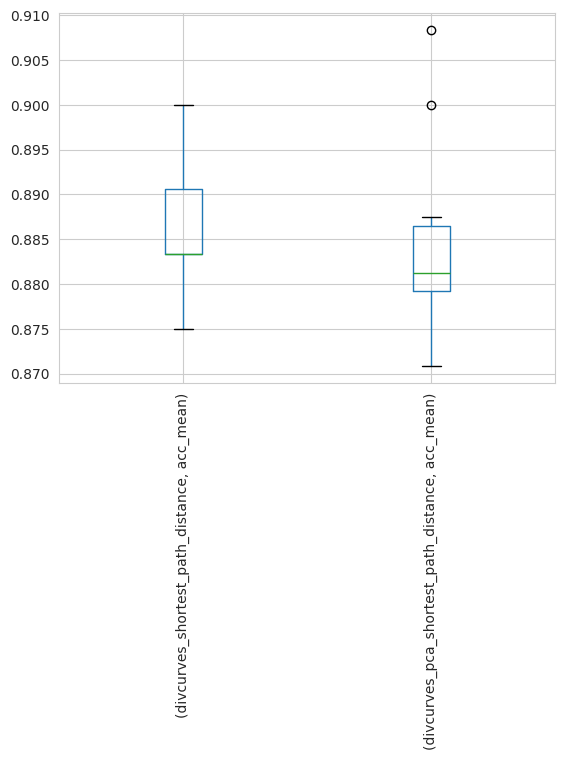

In [7]:
score = 'acc_mean'
mean_scores = res.loc[(slice(None), score),:].transpose()
mean_scores.boxplot()
plt.xticks(rotation=90)
plt.show()

In [8]:
mean_scores

,divcurves_shortest_path_distance,divcurves_pca_shortest_path_distance
,acc_mean,acc_mean
0,0.879167,0.883333
1,0.883333,0.879167
2,0.891667,0.908333
3,0.891667,0.887500
4,0.883333,0.879167
5,0.887500,0.879167
6,0.883333,0.883333
7,0.875000,0.870833
8,0.883333,0.870833


In [9]:
#standard deviation over the mean accuracies
mean_scores.apply(np.std, axis=0)

divcurves_shortest_path_distance      acc_mean    0.006770
divcurves_pca_shortest_path_distance  acc_mean    0.011304
dtype: float64

In [10]:
#mean over the mean accuracies
mean_scores.apply(np.mean, axis=0)

divcurves_shortest_path_distance      acc_mean    0.885833
divcurves_pca_shortest_path_distance  acc_mean    0.884167
dtype: float64

In [46]:
seed_diffs

,0,1,2,3,4,5,6,7,8,9
same_mean,0.506993,0.480206,0.469837,0.462343,0.480330,0.483149,0.486666,0.491054,0.499787,0.473866
same_std,0.347352,0.335434,0.295022,0.298768,0.307972,0.354587,0.341880,0.366853,0.340072,0.307084
rand_mean,12.263367,11.650192,12.627378,12.633120,11.894396,11.641485,11.968437,12.625193,11.552126,12.460145
rand_std,9.145177,8.756282,9.690861,9.322781,9.276527,9.174889,9.047861,9.205363,9.442103,9.406104


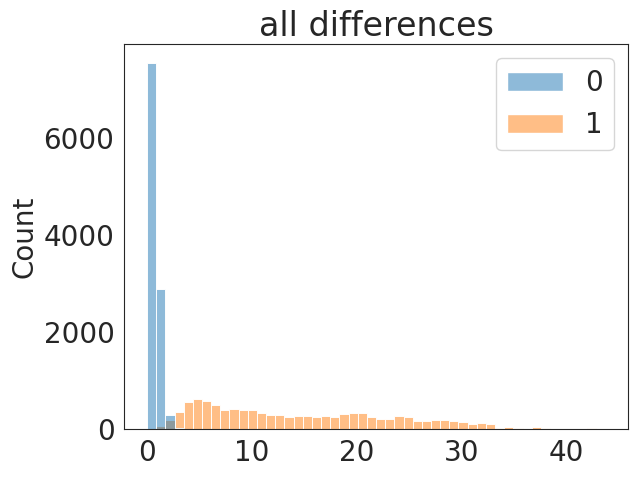

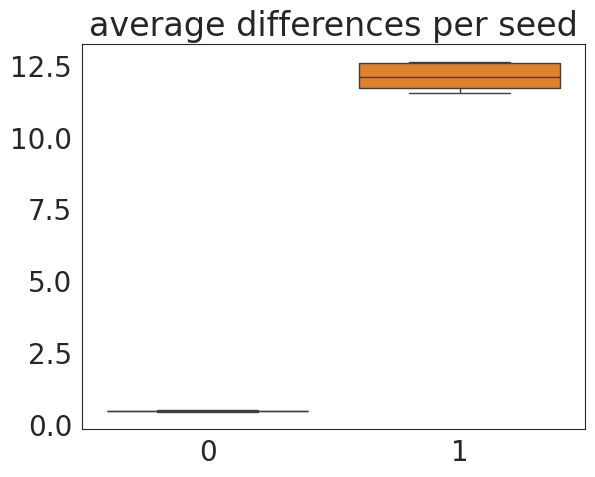

In [49]:
# plotting all differences, so n_seeds*len(G_nx) differences, between the 
# curves from different seeds and the mean curve over all seeds
all_diffs_list = list(all_diffs.loc['same'])
all_rand_diffs_list= list(all_diffs.loc['rand'])

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6.5,5))
# sns.violinplot([all_diffs_model, all_rand_diffs_model])
sns.histplot([all_diffs_list, all_rand_diffs_list])
ax.set_title(f'all differences')
# sns.boxplot([all_diffs_model, all_rand_diffs_model])

#plotting the average mean distance over all graphs per seed, control rand is if we compare a graph to a randomly chosen other graph in the mean curve
seed_diffs_list = list(seed_diffs.loc['same_mean'])
seed_rand_diffs_list = list(seed_diffs.loc['rand_mean'])

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6.5,5))
# sns.violinplot([avg_diffs_model, avg_rand_diffs_model])
# sns.histplot([avg_diffs_model, avg_rand_diffs_model])
sns.boxplot([seed_diffs_list, seed_rand_diffs_list])
ax.set_title(f'average differences per seed')
plt.show()

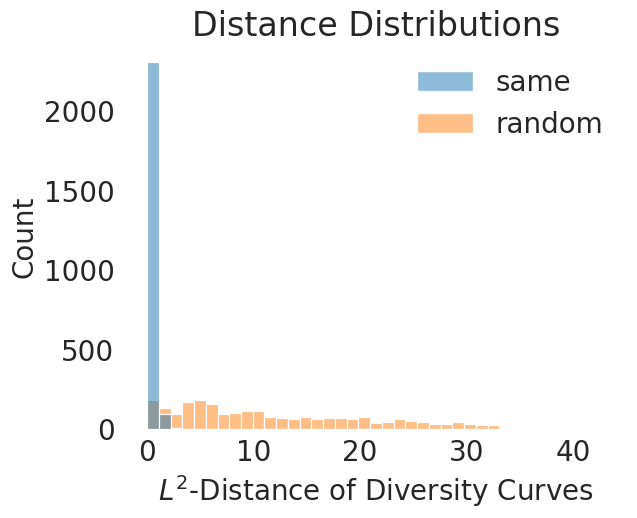

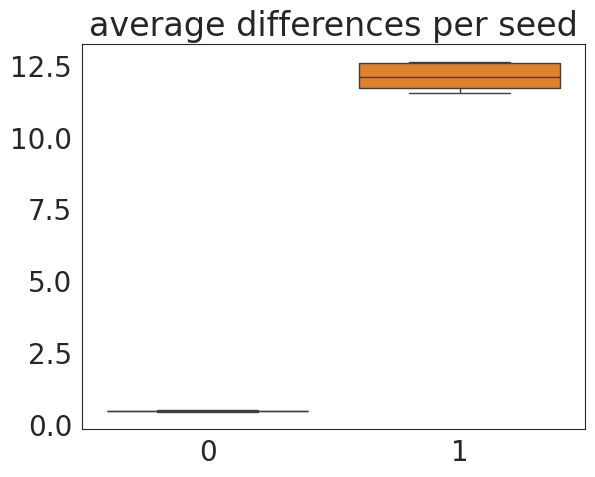

In [ ]:
# plotting all differences, so n_seeds*len(G_nx) differences, between the 
# curves from different seeds and the mean curve over all seeds
all_diffs_list = list(all_diffs_meancurve.loc['same'])
all_rand_diffs_list= list(all_diffs_meancurve.loc['rand'])

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6.5,5))
# sns.violinplot([all_diffs_model, all_rand_diffs_model])
# sns.histplot([all_diffs_list, all_rand_diffs_list])
sns.histplot({'same': all_diffs_list, 'random': all_rand_diffs_list}, ax=ax)
sns.despine()
ax.set_xlabel('$L^2$-Distance of Diversity Curves')
ax.set_title(f'Distance Distributions')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
leg = ax.get_legend()
if leg is not None:
    leg.set_frame_on(False)
# fig.savefig(f'./output/histplot_seed_stability.pdf', bbox_inches='tight', format='pdf')
# sns.boxplot([all_diffs_model, all_rand_diffs_model])

#plotting the average mean distance over all graphs per seed, control rand is if we compare a graph to a randomly chosen other graph in the mean curve
seed_diffs_list = list(seed_diffs.loc['same_mean'])
seed_rand_diffs_list = list(seed_diffs.loc['rand_mean'])

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6.5,5))
# sns.violinplot([avg_diffs_model, avg_rand_diffs_model])
# sns.histplot([avg_diffs_model, avg_rand_diffs_model])
sns.boxplot([seed_diffs_list, seed_rand_diffs_list])
ax.set_title(f'average differences per seed')
plt.show()

In [78]:
len(list(all_diffs_meancurve.loc["same"]))

2400

In [79]:
len(list(all_diffs_meancurve.loc["rand"]))

2400

In [51]:
print(f'Mean and standard deviation over all div curves differences with itself:\n{np.mean(list(all_diffs.loc["same"])), np.std(list(all_diffs.loc["same"]))}')
print(f'Mean and standard deviation over all div curves differences with the mean curve :\n{np.mean(list(all_diffs_meancurve.loc["same"])), np.std(list(all_diffs_meancurve.loc["same"]))}')

Mean and standard deviation over all div curves differences with itself:
(0.7194646413565523, 0.4945797672409662)
Mean and standard deviation over all div curves differences with the mean curve :
(0.48342313427526296, 0.3306197295903247)


In [52]:
print(f'Mean and standard deviation over all div curves rand differences with itself:\n{np.mean(list(all_diffs.loc["rand"])), np.std(list(all_diffs.loc["rand"]))}')
print(f'Mean and standard deviation over all div curves rand differences with the mean curve :\n{np.mean(list(all_diffs_meancurve.loc["rand"])), np.std(list(all_diffs_meancurve.loc["rand"]))}')

Mean and standard deviation over all div curves rand differences with itself:
(14.692282756191632, 9.001309877952163)
Mean and standard deviation over all div curves rand differences with the mean curve :
(12.131583911921132, 9.259340320914275)


## doing the random graph comparison only with graphs with different labels

In [11]:
res_dir = 'simulations/results/ablations/distributions/seed/comp_method_different_group'

all_diffs = pd.read_csv(f'{res_dir}/all_diffs.csv', index_col=0)
seed_diffs = pd.read_csv(f'{res_dir}/seed_diffs.csv', index_col=0)
res = pd.read_csv(f'{res_dir}/res_df.csv', index_col=[0,1])
accs_seed = pd.read_csv(f'{res_dir}/accs_seed.csv', index_col=[0,1], header=0)
accs_seed.index.rename(['method', 'seed'], inplace=True)
all_diffs_meancurve = pd.read_csv(f'{res_dir}/all_diffs_mean.csv', index_col=0)

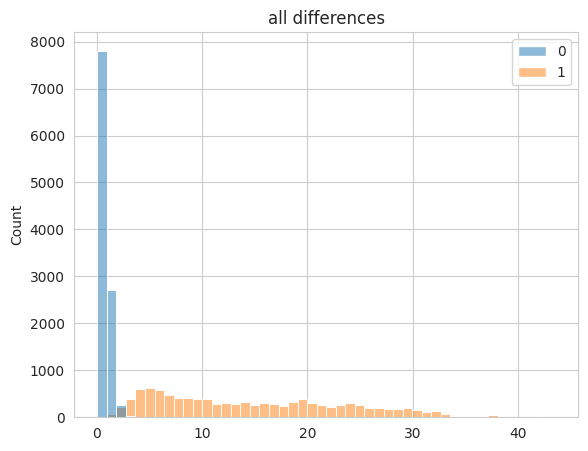

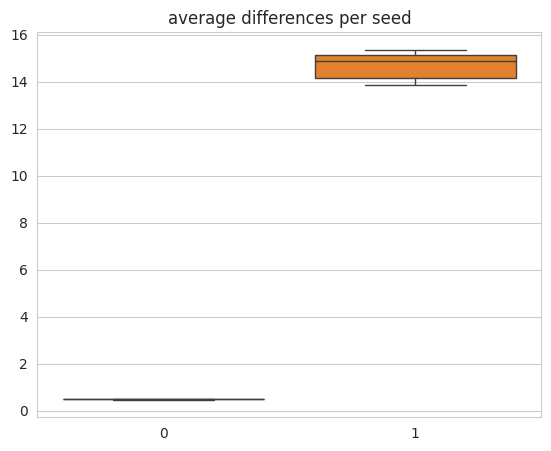

In [12]:
# plotting all differences, so n_seeds*len(G_nx) differences, between the 
# curves from different seeds and the mean curve over all seeds
all_diffs_list = list(all_diffs.loc['same'])
all_rand_diffs_list= list(all_diffs.loc['rand'])

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6.5,5))
# sns.violinplot([all_diffs_model, all_rand_diffs_model])
sns.histplot([all_diffs_list, all_rand_diffs_list])
ax.set_title(f'all differences')
# sns.boxplot([all_diffs_model, all_rand_diffs_model])

#plotting the average mean distance over all graphs per seed, control rand is if we compare a graph to a randomly chosen other graph in the mean curve
seed_diffs_list = list(seed_diffs.loc['same_mean'])
seed_rand_diffs_list = list(seed_diffs.loc['rand_mean'])

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6.5,5))
# sns.violinplot([avg_diffs_model, avg_rand_diffs_model])
# sns.histplot([avg_diffs_model, avg_rand_diffs_model])
sns.boxplot([seed_diffs_list, seed_rand_diffs_list])
ax.set_title(f'average differences per seed')
plt.show()

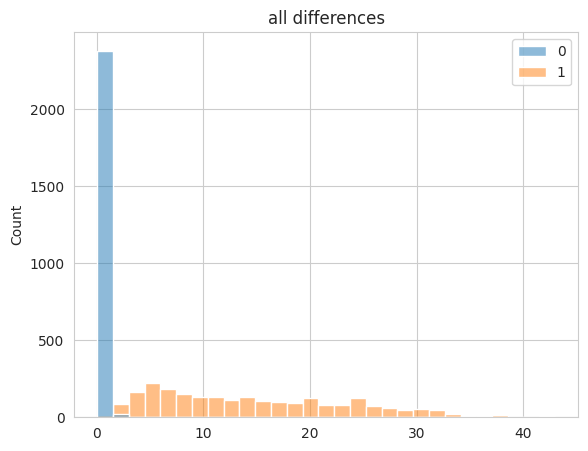

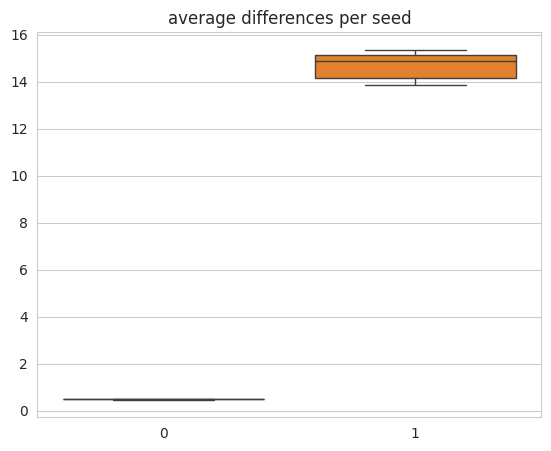

In [13]:
# plotting all differences, so n_seeds*len(G_nx) differences, between the 
# curves from different seeds and the mean curve over all seeds
all_diffs_list = list(all_diffs_meancurve.loc['same'])
all_rand_diffs_list= list(all_diffs_meancurve.loc['rand'])

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6.5,5))
# sns.violinplot([all_diffs_model, all_rand_diffs_model])
sns.histplot([all_diffs_list, all_rand_diffs_list])
ax.set_title(f'all differences')
# sns.boxplot([all_diffs_model, all_rand_diffs_model])

#plotting the average mean distance over all graphs per seed, control rand is if we compare a graph to a randomly chosen other graph in the mean curve
seed_diffs_list = list(seed_diffs.loc['same_mean'])
seed_rand_diffs_list = list(seed_diffs.loc['rand_mean'])

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6.5,5))
# sns.violinplot([avg_diffs_model, avg_rand_diffs_model])
# sns.histplot([avg_diffs_model, avg_rand_diffs_model])
sns.boxplot([seed_diffs_list, seed_rand_diffs_list])
ax.set_title(f'average differences per seed')
plt.show()

In [14]:
len(list(all_diffs.loc["rand"]))

10800

In [15]:
45*240

10800

In [6]:
print(f'Mean and standard deviation over all div curves differences with itself:\n{np.mean(list(all_diffs.loc["same"])), np.std(list(all_diffs.loc["same"]))}')
print(f'Mean and standard deviation over all div curves differences with the mean curve :\n{np.mean(list(all_diffs_meancurve.loc["same"])), np.std(list(all_diffs_meancurve.loc["same"]))}')

Mean and standard deviation over all div curves differences with itself:
(0.7194646413565523, 0.4945797672409662)
Mean and standard deviation over all div curves differences with the mean curve :
(0.48342313427526296, 0.33061972959032476)


In [7]:
print(f'Mean and standard deviation over all div curves rand differences with itself:\n{np.mean(list(all_diffs.loc["rand"])), np.std(list(all_diffs.loc["rand"]))}')
print(f'Mean and standard deviation over all div curves rand differences with the mean curve :\n{np.mean(list(all_diffs_meancurve.loc["rand"])), np.std(list(all_diffs_meancurve.loc["rand"]))}')

Mean and standard deviation over all div curves rand differences with itself:
(14.872330164827497, 9.007260509602844)
Mean and standard deviation over all div curves rand differences with the mean curve :
(14.677166348016533, 8.991539985586519)


### different seed settings

In [16]:
res_dir = 'simulations/results/ablations/distributions/seed/comp_method_different_group/seed_setting_once'

all_diffs = pd.read_csv(f'{res_dir}/all_diffs.csv', index_col=0)
seed_diffs = pd.read_csv(f'{res_dir}/seed_diffs.csv', index_col=0)
res = pd.read_csv(f'{res_dir}/res_df.csv', index_col=[0,1])
accs_seed = pd.read_csv(f'{res_dir}/accs_seed.csv', index_col=[0,1], header=0)
accs_seed.index.rename(['method', 'seed'], inplace=True)
all_diffs_meancurve = pd.read_csv(f'{res_dir}/all_diffs_mean.csv', index_col=0)

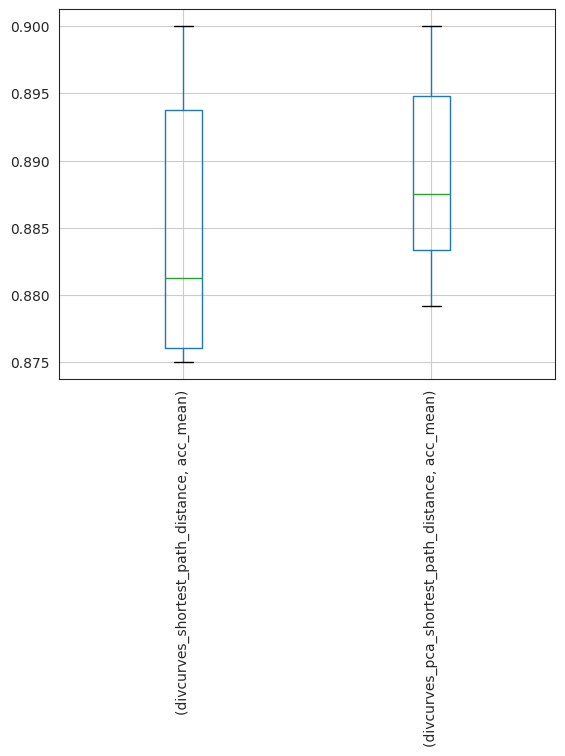

In [17]:
score = 'acc_mean'
mean_scores = res.loc[(slice(None), score),:].transpose()
mean_scores.boxplot()
plt.xticks(rotation=90)
plt.show()

In [18]:
mean_scores

,divcurves_shortest_path_distance,divcurves_pca_shortest_path_distance
,acc_mean,acc_mean
0,0.875000,0.883333
1,0.895833,0.891667
2,0.895833,0.900000
3,0.879167,0.887500
4,0.875000,0.879167
5,0.883333,0.887500
6,0.887500,0.895833
7,0.879167,0.883333
8,0.875000,0.879167


In [19]:
#mean over the mean accuracies
mean_scores.apply(np.mean, axis=0)

divcurves_shortest_path_distance      acc_mean    0.884583
divcurves_pca_shortest_path_distance  acc_mean    0.888750
dtype: float64

In [20]:
#standard deviation over the mean accuracies
mean_scores.apply(np.std, axis=0)

divcurves_shortest_path_distance      acc_mean    0.009138
divcurves_pca_shortest_path_distance  acc_mean    0.007465
dtype: float64

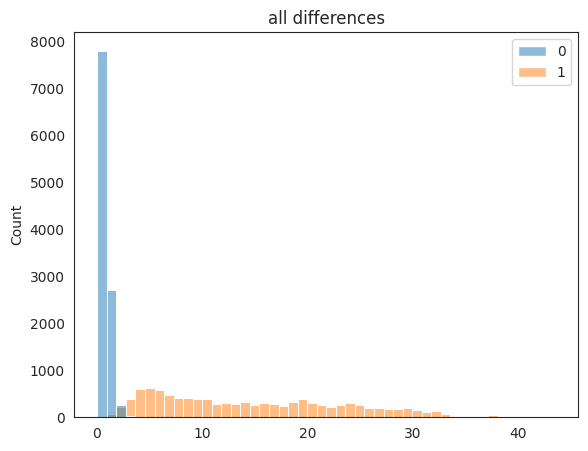

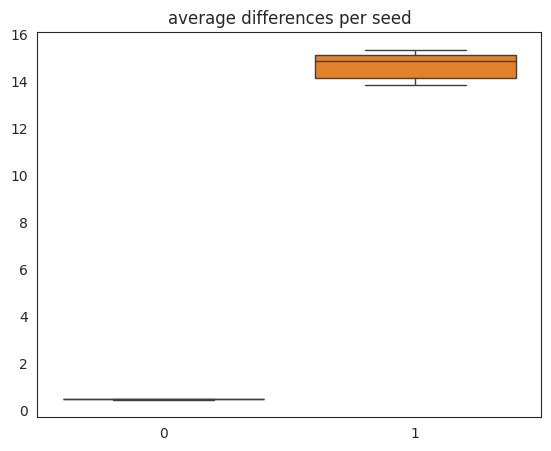

In [21]:
# plotting all differences, so n_seeds*len(G_nx) differences, between the 
# curves from different seeds and the mean curve over all seeds
all_diffs_list = list(all_diffs.loc['same'])
all_rand_diffs_list= list(all_diffs.loc['rand'])

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6.5,5))
# sns.violinplot([all_diffs_model, all_rand_diffs_model])
sns.histplot([all_diffs_list, all_rand_diffs_list])
ax.set_title(f'all differences')
# sns.boxplot([all_diffs_model, all_rand_diffs_model])

#plotting the average mean distance over all graphs per seed, control rand is if we compare a graph to a randomly chosen other graph in the mean curve
seed_diffs_list = list(seed_diffs.loc['same_mean'])
seed_rand_diffs_list = list(seed_diffs.loc['rand_mean'])

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6.5,5))
# sns.violinplot([avg_diffs_model, avg_rand_diffs_model])
# sns.histplot([avg_diffs_model, avg_rand_diffs_model])
sns.boxplot([seed_diffs_list, seed_rand_diffs_list])
ax.set_title(f'average differences per seed')
plt.show()

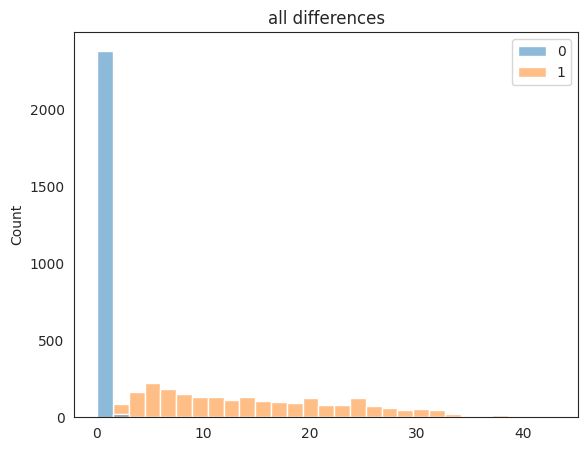

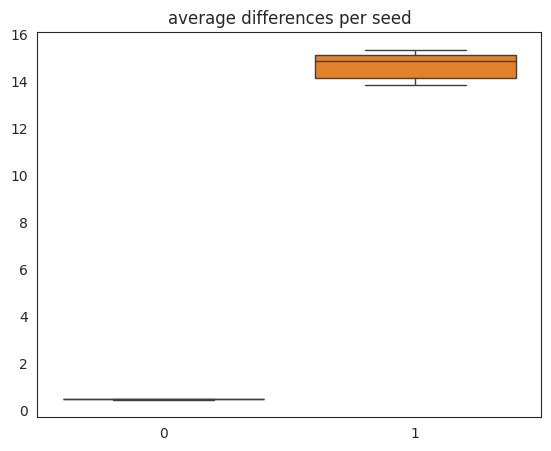

In [22]:
# plotting all differences, so n_seeds*len(G_nx) differences, between the 
# curves from different seeds and the mean curve over all seeds
all_diffs_list = list(all_diffs_meancurve.loc['same'])
all_rand_diffs_list= list(all_diffs_meancurve.loc['rand'])

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6.5,5))
# sns.violinplot([all_diffs_model, all_rand_diffs_model])
sns.histplot([all_diffs_list, all_rand_diffs_list])
ax.set_title(f'all differences')
# sns.boxplot([all_diffs_model, all_rand_diffs_model])

#plotting the average mean distance over all graphs per seed, control rand is if we compare a graph to a randomly chosen other graph in the mean curve
seed_diffs_list = list(seed_diffs.loc['same_mean'])
seed_rand_diffs_list = list(seed_diffs.loc['rand_mean'])

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6.5,5))
# sns.violinplot([avg_diffs_model, avg_rand_diffs_model])
# sns.histplot([avg_diffs_model, avg_rand_diffs_model])
sns.boxplot([seed_diffs_list, seed_rand_diffs_list])
ax.set_title(f'average differences per seed')
plt.show()

In [23]:
print(f'Mean and standard deviation over all div curves differences with itself:\n{np.mean(list(all_diffs.loc["same"])), np.std(list(all_diffs.loc["same"]))}')
print(f'Mean and standard deviation over all div curves differences with the mean curve :\n{np.mean(list(all_diffs_meancurve.loc["same"])), np.std(list(all_diffs_meancurve.loc["same"]))}')

Mean and standard deviation over all div curves differences with itself:
(0.7194646413565523, 0.4945797672409662)
Mean and standard deviation over all div curves differences with the mean curve :
(0.48342313427526296, 0.33061972959032476)


In [24]:
print(f'Mean and standard deviation over all div curves rand differences with itself:\n{np.mean(list(all_diffs.loc["rand"])), np.std(list(all_diffs.loc["rand"]))}')
print(f'Mean and standard deviation over all div curves rand differences with the mean curve :\n{np.mean(list(all_diffs_meancurve.loc["rand"])), np.std(list(all_diffs_meancurve.loc["rand"]))}')

Mean and standard deviation over all div curves rand differences with itself:
(14.872330164827497, 9.007260509602844)
Mean and standard deviation over all div curves rand differences with the mean curve :
(14.677166348016533, 8.991539985586519)


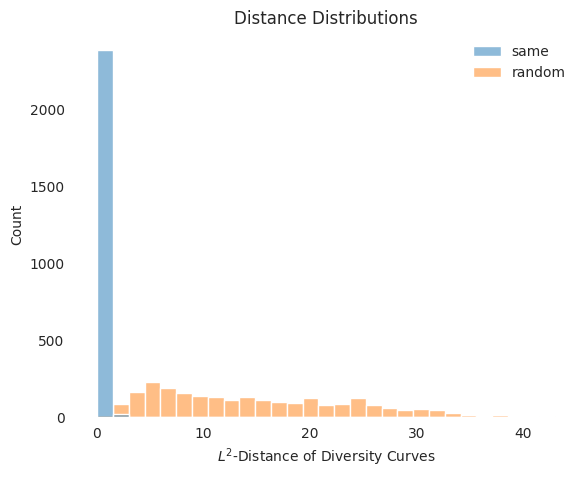

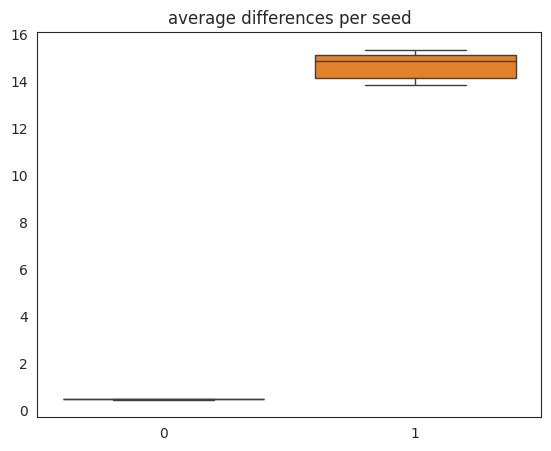

In [25]:
# plotting all differences, so n_seeds*len(G_nx) differences, between the 
# curves from different seeds and the mean curve over all seeds
all_diffs_list = list(all_diffs_meancurve.loc['same'])
all_rand_diffs_list= list(all_diffs_meancurve.loc['rand'])

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6.5,5))
# sns.violinplot([all_diffs_model, all_rand_diffs_model])
# sns.histplot([all_diffs_list, all_rand_diffs_list])
sns.set_style('white')
sns.histplot({'same': all_diffs_list, 'random': all_rand_diffs_list}, ax=ax)
sns.despine()
ax.set_xlabel('$L^2$-Distance of Diversity Curves')
ax.set_title(f'Distance Distributions')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
leg = ax.get_legend()
if leg is not None:
    leg.set_frame_on(False)
# fig.savefig(f'./output/histplot_seed_stability.pdf', bbox_inches='tight', format='pdf')
# sns.boxplot([all_diffs_model, all_rand_diffs_model])

#plotting the average mean distance over all graphs per seed, control rand is if we compare a graph to a randomly chosen other graph in the mean curve
seed_diffs_list = list(seed_diffs.loc['same_mean'])
seed_rand_diffs_list = list(seed_diffs.loc['rand_mean'])

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6.5,5))
# sns.violinplot([avg_diffs_model, avg_rand_diffs_model])
# sns.histplot([avg_diffs_model, avg_rand_diffs_model])
sns.boxplot([seed_diffs_list, seed_rand_diffs_list])
ax.set_title(f'average differences per seed')
plt.show()